# Homework 6 - MTH 602 - Coding Questions

William Girard

Due Date: Wednesday, November 18th, 2026

## Least squares via SGD in JAX (50 POINTS TOTAL)

### Brief recap of the previous assignment for context

In Homework 4 you fit noisy data $\{(t_i, y_i)\}_{i=1}^{N}$ with regularized polynomial least squares by adding $\ell_2$ (ridge) regularization. In this problem, we do not consider any regularization and the equations below specialize to that choice. Given the design matrix $A \in \mathbb{R}^{N \times (M+1)}$ with columns $[1, t, t^2, \dots, t^M]$, we define a loss function

$$
J(\omega) = \frac{1}{N} \sum_{i=1}^{N} \left[ (A\omega)_i - y_i \right]^2, \tag{1}
$$

and the solution to the optimization problem, $\omega_{opt}$, is found by solving

$$
\min_{\omega \in \mathbb{R}^{M+1}} J(\omega).
$$

The solution is given in closed form by the normal equations,

$$
\omega_{opt} = (A^\top A)^{-1} A^\top y, \tag{2}
$$

which can be compared to Eq. (4.27) from the Bishop book.

### Why numerical optimization

As we move into deep learning, closed-form solutions are no longer possible. Instead, the relevant optimization problem must be solved using numerical algorithms implemented in existing code bases.

Before considering a deep learning example, this first problem will have you revisit polynomial least squares but solved using optimization algorithms. The purpose is twofold: (i) gain experience with solving optimization problems numerically with well-tested software and (ii) better understand the behavior of optimizers. Least squares
is an ideal setting for this because we can always compare back to the optimal solution.

You will solve the regression problem using stochastic gradient descent (SGD).

### Dataset and setup

Use the following data generator for this problem:

``` python 

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def generate_data(scale_noise, N, seed=None):
    rng = np.random.default_rng(seed)
    t = np.linspace(0.0, 1.0, N)
    s = 1 + t + t*t
    n = rng.normal(loc=0.0, scale=scale_noise, size=N)
    y = s + n

    return t, y, s, n

t_all, y_all, s_all, n_all = generate_data(0.0, 1000, seed=0)
t_train, t_test, y_train, y_test = train_test_split(t_all,y_all,test_size=0.2,random_state=42)

plt.figure()
plt.plot(t_train, y_train, 'bo', label='training data')
plt.plot(t_test, y_test, 'r+', label='testing data')
plt.legend(); plt.xlabel("t"); plt.ylabel("value"); plt.title("HW4 data + split")
plt.show()
```

### Write and test the model and loss functions (10 POINTS)

Consider a fixed degree $M$. Now define the Vandermonde design matrix $A$ through evaluation of the polynomial basis functions at the requested sample points $\vec{t}$. Write three JAX functions with the following input/output structure:

1. **(Model)**. Input: vector of weights ($\vec{\omega}$) and the matrix ($A$). Output: model evaluation $A\vec{\omega}$.
2. **(Loss)**. Input: vector of weights ($\vec{\omega}$), the matrix ($A$), and the data ($\vec{y}$) on which to compute the loss. Output: the value of the loss according to Eq. (1).
3. **(MSE)**. Input: the data ($\vec{y}$) and corresponding model evaluations. Output: the mean squared error.

For regression problems, as before, it will be important to distinguish between the MSE (or loss) evaluated on the testing and training sets. For example, the MSE on the training data is:

$$
\text{Training error:} \quad = \frac{1}{N_{\text{train}}} \sum_{i=1}^{N_{\text{train}}} \left[ y_i^{\text{train}} - y_{\text{model}}(t_i^{\text{train}}) \right]^2 \tag{3}
$$

And we can use the testing data to monitor the generalization error during the training process by computing:

$$
\text{Generalization error:} \quad = \frac{1}{N_{\text{test}}} \sum_{i=1}^{N_{\text{test}}} \left[ y_i^{\text{test}} - y_{\text{model}}(t_i^{\text{test}}) \right]^2 \tag{4}
$$

**Report on the following**: Please provide evidence that your model and loss function are working as expected. That is, you should design and report on a simple test (a sanity test) for this task. The point here is to build confidence in your functions' correctness.

In [1]:
# since the homework allows any library, I'm going to use PyTorch since I am more familiar

!pip install torch==2.14.1 torchvision==0.29.1 --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 6.7 MB/s  0:01:11 eta 0:00:010:00:03
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 6.5 MB/s  0:00:26 eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 7.6 MB/s  0:00:07a 0:00:010:00:01:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 7.6 MB/s  0:00:59 eta 0:00:010:00:02
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 7.7 MB/s  0:00:11 eta 0:00:010:01:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 8.5 MB/s  0:00:008.4 MB/s eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 7.1 MB/s  0:00:30 eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.5/42.5 MB 6.7 MB/s  0:00:06a 0:00:01m eta 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 8.1 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 8.3 MB/s  0:00:018.4 MB/s eta

In [1]:
import torch
print(torch.__version__)

2.14.1+cu130


In [2]:
torch.set_default_dtype(torch.float64) # set 64 bit precision

In [3]:
import torch
import numpy as np 

seed = 42

torch.manual_seed(seed)
np.random.seed(seed)

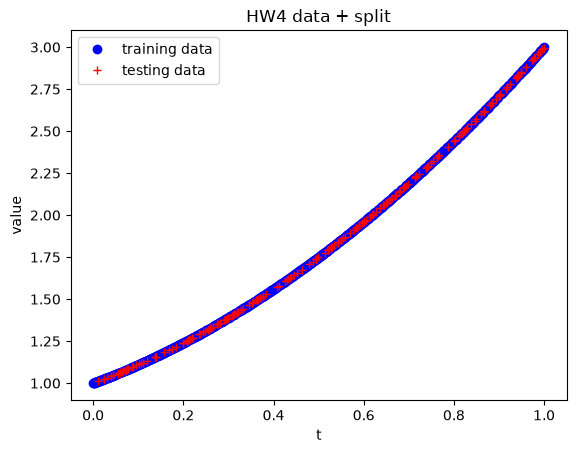

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def generate_data(scale_noise, N, seed=None):
    rng = np.random.default_rng(seed)
    t = np.linspace(0.0, 1.0, N)
    s = 1 + t + t*t
    n = rng.normal(loc=0.0, scale=scale_noise, size=N)
    y = s + n

    return t, y, s, n

t_all, y_all, s_all, n_all = generate_data(0.0, 1000, seed=0)
t_train, t_test, y_train, y_test = train_test_split(t_all,y_all,test_size=0.2,random_state=42)

plt.figure()
plt.plot(t_train, y_train, 'bo', label='training data')
plt.plot(t_test, y_test, 'r+', label='testing data')
plt.legend(); plt.xlabel("t"); plt.ylabel("value"); plt.title("HW4 data + split")
plt.show()

In [5]:
from sklearn.metrics import mean_squared_error # MSE is the metric

In [6]:
# optimize the weight vector
# has M+1 elements (bc of intercept) and requires gradient, meaning it can be optimized

M = 8 # example
omega = torch.zeros(M + 1, requires_grad=True, dtype=torch.float64)
omega.shape

torch.Size([9])

In [7]:
# construct matrix A, pulled from homework 4
def design_matrix(t, M):
    A = np.vander(x=t, N=M+1, increasing=True)
    return A

In [8]:
# sanity check: leave all weights in omega as 0
# in which case MSE should equal the average value y^2

A_train = design_matrix(t_train, M)
A_test = design_matrix(t_test, M)

y_train_pred = torch.from_numpy(A_train) @ omega # leave omegas as all zeros
train_MSE = mean_squared_error(y_train, y_train_pred.detach().numpy())

y_test_pred = torch.from_numpy(A_test) @ omega 
test_MSE = mean_squared_error(y_test, y_test_pred.detach().numpy())

print(f'Train MSE: {train_MSE} - y train mean: {np.mean(y_train**2)}')
print(f'Test MSE: {test_MSE} - y test mean: {np.mean(y_test**2)}')

Train MSE: 3.687386876282884 - y train mean: 3.687386876282884
Test MSE: 3.756959168208304 - y test mean: 3.756959168208304


The above code just verifies the most basic case I could think of: all zero weights with no predictive power, so the MSE is the maximum every single time. As expected, the full loop with $\vec{\omega} = 0$ produces the exact same train/test MSE as just squaring every y value and taking the mean. Now that everything seems to be set-up correctly, its time to optimize $\omega$.

### Optimizing with stochastic gradient descent (10 POINTS)

1. Write code that implements a training loop that (per epoch) logs train/test MSE.

In [50]:
# compute closed form solution first using PyTorch 
M = 3
A_train = design_matrix(t_train, M)
A_test = design_matrix(t_test, M)
omega = torch.zeros(M + 1, requires_grad=True, dtype=torch.float64)

omega_opt = torch.linalg.lstsq(torch.from_numpy(A_train), torch.from_numpy(y_train)).solution
omega_opt

tensor([1.0000e+00, 1.0000e+00, 1.0000e+00, 4.5809e-15])

In [ ]:
epochs = 100000
l2_norm_list, test_loss_list, train_loss_list = [], [], []

optimizer = torch.optim.SGD([omega], lr=0.2)
A_train_tensor = torch.from_numpy(A_train)

for epoch in range(epochs): 
    
    optimizer.zero_grad()

    # make predictions
    y_pred = A_train_tensor @ omega

    # compute loss 
    loss = torch.nn.functional.mse_loss(y_pred, torch.from_numpy(y_train))
    train_loss_list.append(loss.item())
    loss.backward() 
    optimizer.step()

    with torch.no_grad():
        dist_to_opt = torch.norm(omega - omega_opt, p=2).item()
        l2_norm_list.append(dist_to_opt)

        # predict on test set
        y_test_pred = torch.from_numpy(A_test) @ omega
        test_loss = torch.nn.functional.mse_loss(y_test_pred, torch.from_numpy(y_test)).item()
        test_loss_list.append(test_loss)

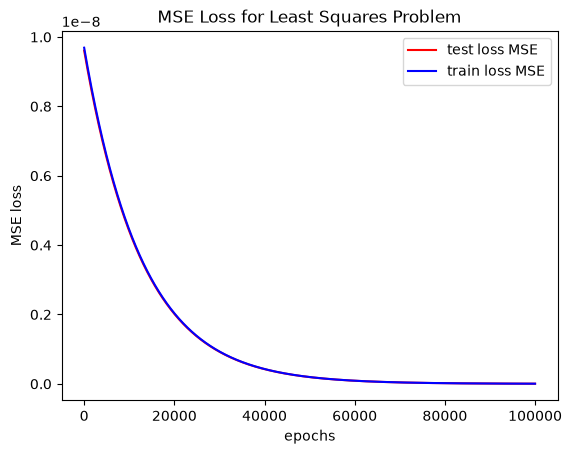

In [25]:
plt.figure()
plt.plot(list(range(epochs)), test_loss_list, color="red", label="test loss MSE")
plt.plot(list(range(epochs)), train_loss_list, color="blue", label="train loss MSE")
plt.legend()
plt.xlabel("epochs")
plt.ylabel('MSE loss')
plt.title("MSE Loss for Least Squares Problem")
plt.show()

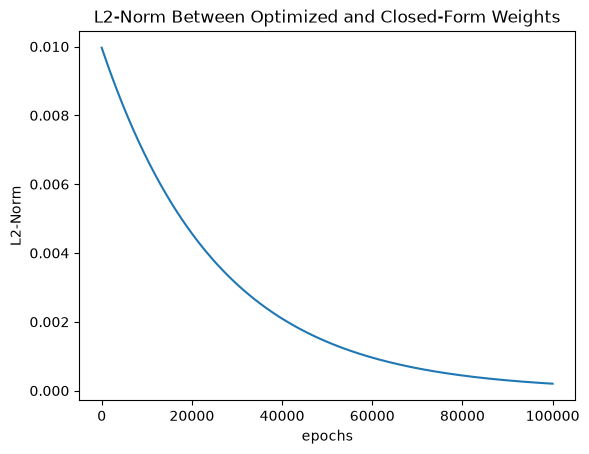

In [26]:
plt.figure()
plt.plot(list(range(epochs)), l2_norm_list)
plt.xlabel("epochs")
plt.ylabel("L2-Norm")
plt.title("L2-Norm Between Optimized and Closed-Form Weights")
plt.show()

In [35]:
print(f'Final optimized weights: {omega}')
print(f'Closed-form weights: {omega_opt}')
print(f'Final L2-Norm: {torch.norm(omega - omega_opt, p=2).item()}')

Final optimized weights: tensor([9.9999e-01, 1.0001e+00, 9.9984e-01, 1.0404e-04], requires_grad=True)
Closed-form weights: tensor([1.0000e+00, 1.0000e+00, 1.0000e+00, 4.5809e-15])
Final L2-Norm: 0.00020140042716937031


2. Generalize what you did in part 1 to iterate over batches of the training set for each epoch.

In [ ]:
import time 

import time
import torch

def training_loop(A_train, A_test, y_train, y_test, omega_opt, omega, epochs, batch_size, optimizer): 

    start = time.time() 

    l2_norm_list, test_loss_list, train_loss_list = [], [], []

    # convert everything to a torch tensor at the start 
    A_train_tensor = torch.as_tensor(A_train, dtype=torch.float64)
    A_test_tensor = torch.as_tensor(A_test, dtype=torch.float64) 
    y_train_tensor = torch.as_tensor(y_train, dtype=torch.float64)
    y_test_tensor = torch.as_tensor(y_test, dtype=torch.float64)
    omega_opt_tensor = torch.as_tensor(omega_opt, dtype=torch.float64)

    assert batch_size <= len(A_train), "Batch size cannot exceed the size of the dataset" 

    train_loss, test_loss = 0, 0

    for epoch in range(epochs + 1): 

        if epoch % 1000 == 0: 
            print(f'{epoch}/{epochs} | Train Loss: {train_loss:.3E} | Test Loss: {test_loss:.3E}')

        # shuffle the rows of A_train each epoch 
        perm = torch.randperm(len(A_train))
        A_train_tensor_shuffled = A_train_tensor[perm]
        y_train_tensor_shuffled = y_train_tensor[perm]

        for start_idx in range(0, len(A_train), batch_size):
            end_idx = start_idx + batch_size

            optimizer.zero_grad(set_to_none=True)

            # make predictions
            y_pred = A_train_tensor_shuffled[start_idx:end_idx] @ omega

            # compute loss 
            loss = torch.nn.functional.mse_loss(y_pred, y_train_tensor_shuffled[start_idx:end_idx])
            loss.backward() 
            optimizer.step()

        # test once per epoch
        with torch.no_grad():
            dist_to_opt = torch.norm(omega - omega_opt_tensor, p=2).item()
            l2_norm_list.append(dist_to_opt)

            # full test loss after all batches
            y_train_pred = A_train_tensor @ omega 

            train_loss = torch.nn.functional.mse_loss(y_train_pred, y_train_tensor).item()
            train_loss_list.append(train_loss)

            # predict on test set
            y_test_pred = A_test_tensor @ omega
            test_loss = torch.nn.functional.mse_loss(y_test_pred, y_test_tensor).item()
            test_loss_list.append(test_loss)

    end = time.time()
    total_time = end - start  

    return {
        'training_loss': train_loss_list,
        'test_loss': test_loss_list, 
        'l2_norm': l2_norm_list,
        'omega': omega.detach().clone(),
        'time': round(total_time, 2)
    }

M = 3
A_train = design_matrix(t_train, M)
A_test = design_matrix(t_test, M)
omega = torch.zeros(M + 1, requires_grad=True, dtype=torch.float64)

omega_opt = torch.linalg.lstsq(torch.from_numpy(A_train), torch.from_numpy(y_train)).solution
opt = torch.optim.SGD([omega], lr=0.2)

results = training_loop(A_train, A_test, y_train, y_test, omega_opt, omega, epochs=10000, batch_size=16, optimizer=opt)


0/10000 | Train Loss: 0.000E+00 | Test Loss: 0.000E+00
1000/10000 | Train Loss: 4.731E-07 | Test Loss: 4.694E-07
2000/10000 | Train Loss: 9.442E-09 | Test Loss: 9.369E-09
3000/10000 | Train Loss: 1.885E-10 | Test Loss: 1.870E-10
4000/10000 | Train Loss: 3.762E-12 | Test Loss: 3.733E-12
5000/10000 | Train Loss: 7.508E-14 | Test Loss: 7.450E-14
6000/10000 | Train Loss: 1.499E-15 | Test Loss: 1.487E-15
7000/10000 | Train Loss: 2.991E-17 | Test Loss: 2.968E-17
8000/10000 | Train Loss: 5.971E-19 | Test Loss: 5.924E-19
9000/10000 | Train Loss: 1.192E-20 | Test Loss: 1.182E-20
10000/10000 | Train Loss: 2.379E-22 | Test Loss: 2.360E-22


3. Batch size study (10 POINTS)

Fix 𝑀 = 3 and set the learning rate to 𝛼 = .1. Train with 𝐵 ∈ {1, 16, 64, 𝑁train } for 100,000 epochs. For each
different value of 𝐵 plot the training and testing MSE vs. epoch. Also measure the typical time (using some
measurement for timing the code like tic-toc) to a target test MSE. Discuss any interesting observations. Note
that during SGD training, the loss function 𝐽 is evaluated on a mini-batch, so in Eq. (1) use 𝑁 = 𝐵 and 𝐴, 𝑦 are
restricted to the rows in that batch.

In [68]:
M = 3
A_train = design_matrix(t_train, M)
A_test = design_matrix(t_test, M)
omega = torch.zeros(M + 1, requires_grad=True, dtype=torch.float64)

omega_opt = torch.linalg.lstsq(torch.from_numpy(A_train), torch.from_numpy(y_train)).solution
opt = torch.optim.SGD([omega], lr=0.1)

B = [1, 16, 64, len(A_train)]

full_results = {}

for b in B: 

    print(f'Testing batch size of {b}...')
    results = training_loop(A_train, A_test, y_train, y_test, omega_opt, omega, epochs=100000, batch_size=b, optimizer=opt)
    print(f'Training completed in {results["time"]} seconds!')

    full_results[b] = results


Testing batch size of 1...
0/100000 | Train Loss: 0.000E+00 | Test Loss: 0.000E+00
1000/100000 | Train Loss: 5.958E-19 | Test Loss: 6.019E-19


KeyboardInterrupt: 